<a href="https://colab.research.google.com/github/Abidau/MachineLearning/blob/main/TG15_244107020212_NaufalAbidAurizky.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1

## Langkah 1 - Import Library dan Mount Google Drive

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Langkah 2 - Load Dataset

In [2]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = "/content/drive/MyDrive/ML/images/training/"
test_dir  = "/content/drive/MyDrive/ML/images/test"

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print(f"Jumlah data training: {len(train_img)}")
print(f"Jumlah data testing: {len(test_img)}")

Jumlah data training: 240
Jumlah data testing: 160


## Langkah 3 - Preprocessing (Resize & Label Encoding)

In [3]:
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

## Langkah 4 - Ekstraksi Fitur HOG (Histogram of Oriented Gradients)

In [4]:
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

## Langkah 5 - Normalisasi Fitur

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

## Langkah 6 - Split Data Training & Validation

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

## Langkah 7 - Konversi Label ke Numpy Array

In [7]:
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

## Langkah 8 - Membangun Arsitektur Model Neural Network

In [8]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

## Langkah 9 - Training Model

In [9]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 111ms/step - accuracy: 0.8594 - loss: 0.6554 - val_accuracy: 0.9792 - val_loss: 0.0683
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.9740 - loss: 0.2566 - val_accuracy: 1.0000 - val_loss: 0.0029
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.9792 - loss: 0.1821 - val_accuracy: 1.0000 - val_loss: 0.0016
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 1.0000 - loss: 5.7499e-04 - val_accuracy: 0.8958 - val_loss: 0.8440
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - accuracy: 0.9896 - loss: 0.0366 - val_accuracy: 1.0000 - val_loss: 5.3336e-04
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 1.0000 - loss: 5.7988e-06 - val_accuracy: 1.0000 - val_loss: 8.6600e-04
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 1.0000 - loss: 5.2578e-06 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - accuracy: 1.0000 - loss: 5.2482e-06 - val_accuracy: 

## Langkah 10 - Evaluasi Model

In [10]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Akurasi Test:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9250 - loss: 0.5637
Akurasi Test: 0.925000011920929


## Langkah 11 - Prediksi dan Laporan Klasifikasi serta Visualisasi

In [11]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
              precision    recall  f1-score   support

           0       0.94      0.91      0.92        80
           1       0.91      0.94      0.93        80

    accuracy                           0.93       160
   macro avg       0.93      0.93      0.92       160
weighted avg       0.93      0.93      0.92       160

[[73  7]
 [ 5 75]]


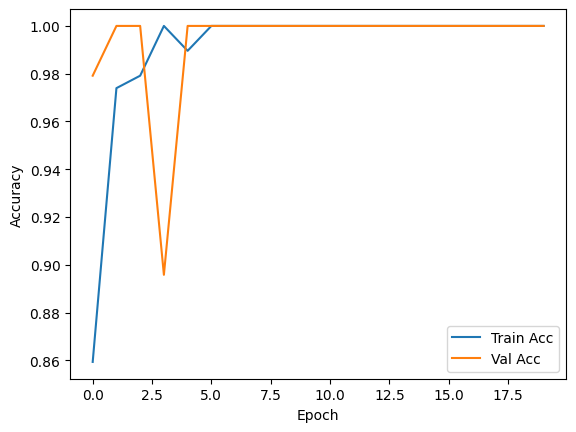

In [12]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

## Langkah 12 - Menyimpan Model dan Scaler

In [13]:
# Save the trained model
import pickle

# 1. Simpan Model
# Menggunakan format .h5
model.save('day_night_model.h5')
print("✅ Model berhasil disimpan sebagai: day_night_model.h5")

# 2. Simpan Scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("✅ Scaler berhasil disimpan sebagai: scaler.pkl")

✅ Model berhasil disimpan sebagai: day_night_model.h5
✅ Scaler berhasil disimpan sebagai: scaler.pkl


# Praktikum 2
## Hasil Uji Deployment Model Day vs Night (Flask + Docker)

### Tujuan
Menguji penyajian model klasifikasi gambar Day vs Night (fitur HOG + Neural Network) sebagai aplikasi web Flask yang dijalankan di dalam Docker container.

### Ringkasan Hasil

| Komponen | Hasil |
|---|---|
| Docker Engine | Berjalan (Docker Desktop 4.99.0, Engine 29.9.3) |
| Build image `daynight` | Berhasil, 250,5 detik (13/13 tahap) |
| Aplikasi Flask di container | Berjalan di `http://localhost:7860` |
| Endpoint `/predict` | Berhasil: **Day (Siang)**, keyakinan **99,91%** |

> **Catatan:** Docker Space di Hugging Face saat ini berstatus berbayar (*Paid*), sehingga pengujian dilakukan secara lokal menggunakan Docker Desktop dengan konfigurasi yang sama seperti yang akan dipakai di server.

### 1. Konfigurasi Proyek

| File | Fungsi |
|---|---|
| `app.py` | Server Flask: memuat model & scaler, preprocessing HOG, prediksi |
| `requirements.txt` | Daftar library (versi dikunci sama dengan environment training) |
| `Dockerfile` | Image `python:3.11-slim`, install dependencies, jalankan gunicorn di port 7860 |
| `.dockerignore` | Mengecualikan file yang tidak perlu masuk ke image |
| `day_night_model.h5`, `scaler.pkl` | Model dan scaler hasil Praktikum 1 |

In [14]:
import os, shutil
PROJECT = '/content/daynight-project'
os.makedirs(PROJECT, exist_ok=True)

for f in ['day_night_model.h5', 'scaler.pkl']:
    shutil.copy(f'/content/{f}', f'{PROJECT}/{f}')

%cd /content/daynight-project
!ls -lh

/content/daynight-project
total 52M
-rw-r--r-- 1 root root  51M Nov 19 05:26 day_night_model.h5
-rw-r--r-- 1 root root 812K Nov 19 05:26 scaler.pkl


#### `app.py`

In [15]:
%%writefile app.py
import os
import pickle

import cv2
import numpy as np
import tensorflow as tf
from flask import Flask, request, render_template_string
from skimage.feature import hog

app = Flask(__name__)
app.config["MAX_CONTENT_LENGTH"] = 10 * 1024 * 1024  # batas upload 10 MB

# ---------------------------------------------------------------
# Load Model & Scaler (path absolut agar aman dijalankan dari mana saja)
# ---------------------------------------------------------------
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(BASE_DIR, "day_night_model.h5")
SCALER_PATH = os.path.join(BASE_DIR, "scaler.pkl")

# Tidak dibungkus try/except: kalau gagal load, aplikasi harus berhenti
# dan error-nya terlihat jelas di log (terminal Docker).
model = tf.keras.models.load_model(MODEL_PATH, compile=False)
with open(SCALER_PATH, "rb") as f:
    scaler = pickle.load(f)
print("✅ System Loaded Successfully")


def preprocess_image(image_bytes):
    """Preprocessing harus sama persis dengan saat training."""
    nparr = np.frombuffer(image_bytes, np.uint8)
    img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError("File bukan gambar yang valid (gunakan JPG/PNG).")

    img = cv2.resize(img, (256, 256))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    hog_feat = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        visualize=False,
        feature_vector=True,
    )
    return scaler.transform(hog_feat.reshape(1, -1))


PAGE = """
<!doctype html>
<html lang="id">
<head>
  <meta charset="utf-8">
  <meta name="viewport" content="width=device-width, initial-scale=1">
  <title>Day vs Night Classifier</title>
</head>
<body style="font-family:sans-serif; text-align:center; padding:50px;">
  {{ body|safe }}
</body>
</html>
"""

HOME = """
<h1>Day vs Night Classifier</h1>
<form action="/predict" method="post" enctype="multipart/form-data">
  <input type="file" name="file" accept="image/*" required><br><br>
  <button type="submit">Prediksi</button>
</form>
"""


@app.route("/", methods=["GET"])
def home():
    return render_template_string(PAGE, body=HOME)


@app.route("/health", methods=["GET"])
def health():
    return {"status": "ok"}


@app.route("/predict", methods=["POST"])
def predict():
    try:
        file = request.files.get("file")
        if file is None or file.filename == "":
            raise ValueError("Tidak ada file yang diunggah.")

        data = preprocess_image(file.read())
        prob_day = float(model.predict(data, verbose=0)[0][0])

        # Saat training: day = 1, night = 0
        if prob_day > 0.5:
            label, confidence = "Day (Siang)", prob_day
        else:
            label, confidence = "Night (Malam)", 1 - prob_day

        body = (
            f"<h2>Hasil: {label}</h2>"
            f"<p>Keyakinan: {confidence * 100:.2f}%</p>"
            "<a href='/'>Kembali</a>"
        )
    except Exception as e:
        body = f"<h2>Error</h2><p>{e}</p><a href='/'>Kembali</a>"
    return render_template_string(PAGE, body=body)


if __name__ == "__main__":
    # Dijalankan langsung: python app.py  (port bisa diubah lewat env PORT)
    port = int(os.environ.get("PORT", 7860))
    app.run(host="0.0.0.0", port=port)


Writing app.py


#### `requirements.txt`
Versi library dikunci sama dengan environment Colab agar `scaler.pkl` dan model `.h5` terbaca dengan benar.

In [16]:
import tensorflow as tf, sklearn, skimage, numpy

reqs = f"""flask
tensorflow-cpu=={tf.__version__}
numpy=={numpy.__version__}
scikit-learn=={sklearn.__version__}
scikit-image=={skimage.__version__}
opencv-python-headless
gunicorn
"""
with open('requirements.txt', 'w') as f:
    f.write(reqs)
print(reqs)

flask
tensorflow-cpu==2.21.0
numpy==2.4.6
scikit-learn==1.6.1
scikit-image==0.25.2
opencv-python-headless
gunicorn



Hasil pada environment pengujian:

```
flask
tensorflow-cpu==2.21.0
numpy==2.4.6
scikit-learn==1.6.1
scikit-image==0.25.2
opencv-python-headless
gunicorn
```

#### `Dockerfile`

In [17]:
%%writefile Dockerfile
# Base image Python 3.11 Slim
FROM python:3.11-slim

# Library sistem untuk OpenCV
RUN apt-get update && apt-get install -y --no-install-recommends \
    libglib2.0-0 \
    && rm -rf /var/lib/apt/lists/*

# Jalankan sebagai user non-root (praktik keamanan yang baik)
RUN useradd -m -u 1000 user
USER user
ENV PATH="/home/user/.local/bin:$PATH" \
    TF_CPP_MIN_LOG_LEVEL=2 \
    PORT=7860

WORKDIR /app

# Install dependencies (di-cache selama requirements.txt tidak berubah)
COPY --chown=user ./requirements.txt requirements.txt
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Copy file aplikasi
COPY --chown=user . /app

EXPOSE 7860

# Jalankan dengan gunicorn (production server)
CMD ["sh", "-c", "gunicorn -b 0.0.0.0:${PORT} -w 1 --threads 2 --timeout 120 app:app"]


Writing Dockerfile


#### `.dockerignore`

In [18]:
%%writefile .dockerignore
venv/
__pycache__/
*.pyc
*.ipynb
.git/

Writing .dockerignore


#### Pengemasan proyek

In [19]:
%cd /content
!zip -r daynight-project.zip daynight-project -x "*/__pycache__/*"
from google.colab import files
files.download('daynight-project.zip')

/content
  adding: daynight-project/ (stored 0%)
  adding: daynight-project/app.py (deflated 50%)
  adding: daynight-project/requirements.txt (deflated 17%)
  adding: daynight-project/Dockerfile (deflated 37%)
  adding: daynight-project/scaler.pkl (deflated 7%)
  adding: daynight-project/day_night_model.h5 (deflated 8%)
  adding: daynight-project/.dockerignore (deflated 3%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 2. Hasil Pengujian

#### 2.1 Docker Engine
Perintah `docker version` menampilkan bagian *Client* dan *Server*, sehingga Docker Engine aktif:

```
Server: Docker Desktop 4.99.0 (245822)
 Engine:
  Version:          29.9.3
  API version:      1.56 (minimum version 1.40)
  OS/Arch:          linux/amd64
```

#### 2.2 Build Docker Image
Perintah `docker build -t daynight .` selesai tanpa error:

```
[+] Building 250.5s (13/13) FINISHED
 => [6/7] RUN pip install --no-cache-dir --upgrade -r requirements.txt     175.8s
 => => naming to docker.io/library/daynight:latest
```

Tahap terlama adalah instalasi dependencies (`pip install`, 175,8 detik) karena TensorFlow.

#### 2.3 Menjalankan Container
Perintah `docker run -p 7860:7860 daynight` menjalankan aplikasi Flask melalui gunicorn dan dapat diakses di `http://localhost:7860`.

#### 2.4 Hasil Prediksi
Gambar uji diunggah melalui form pada aplikasi. Hasil prediksi pada endpoint `/predict`:

| Gambar uji | Label prediksi | Keyakinan |
|---|---|---|
| Gambar 1 | Day (Siang) | 99,91% |

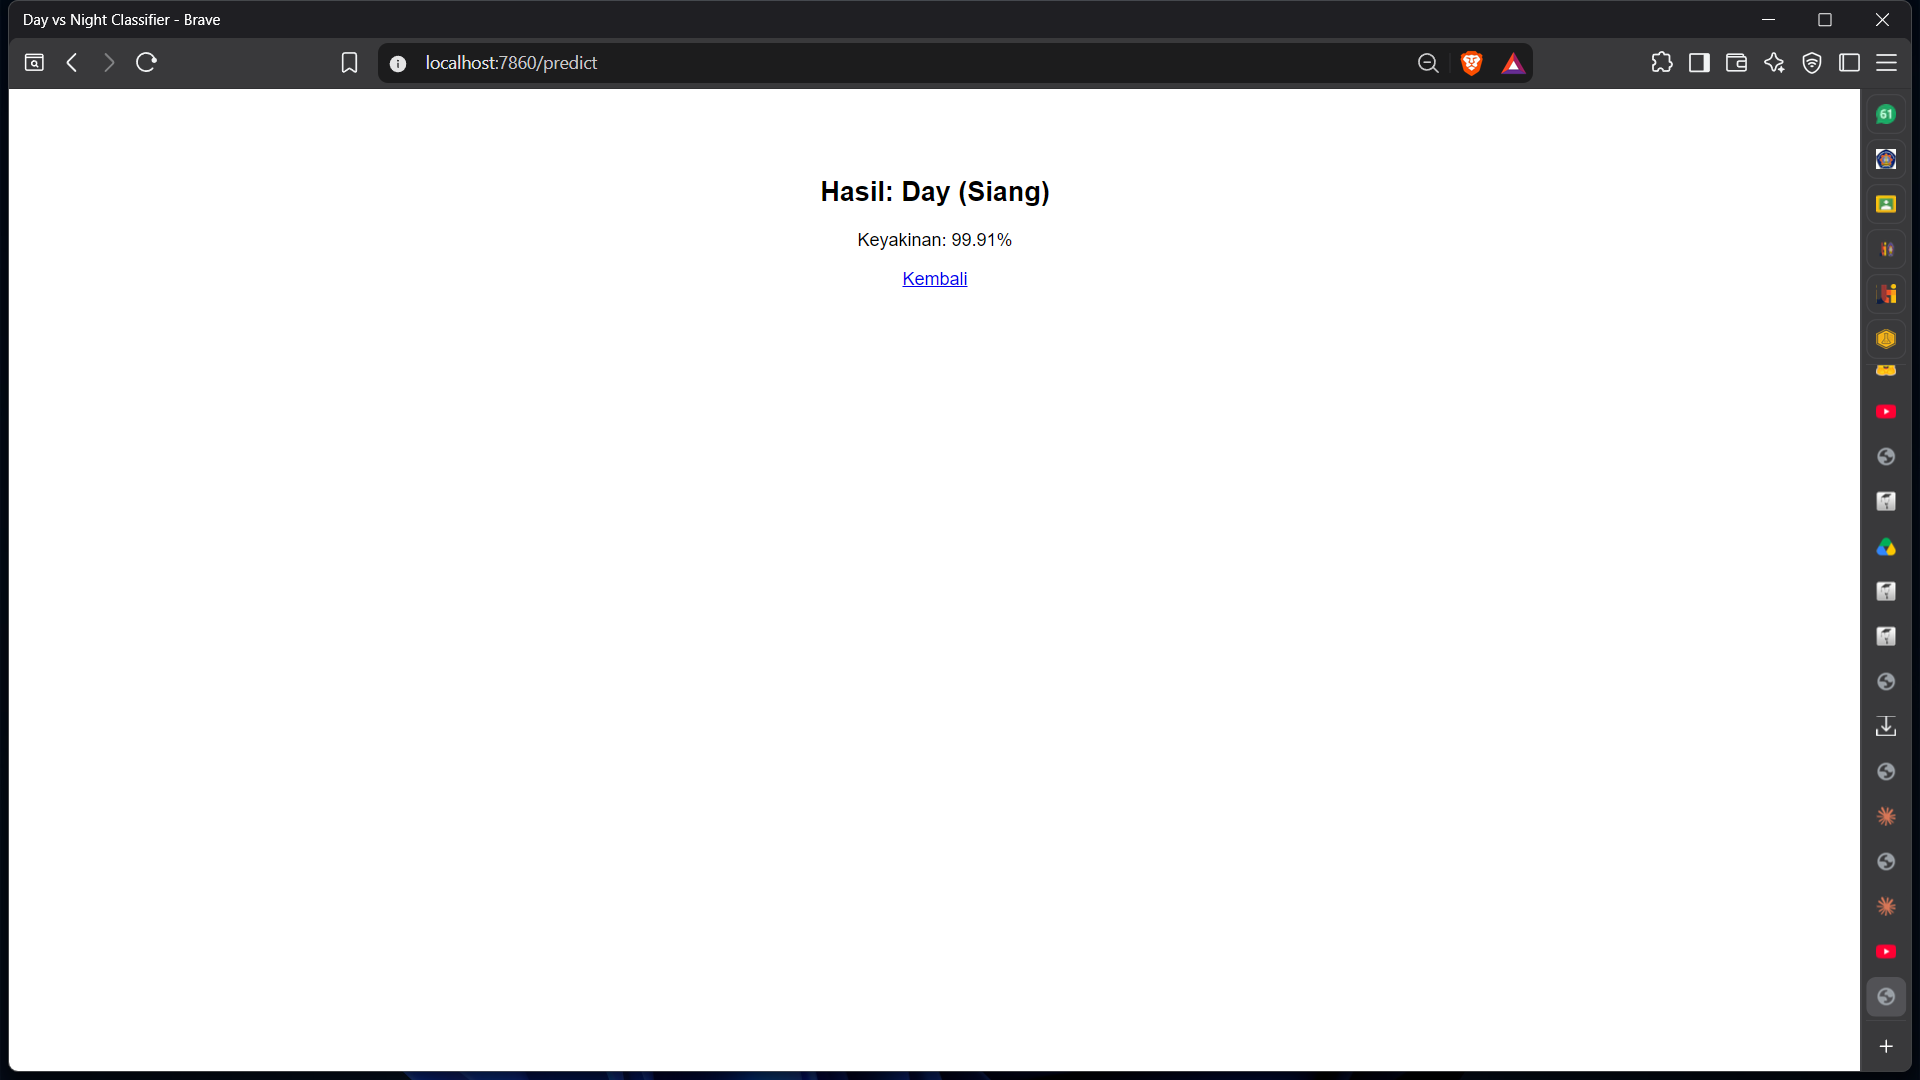

Gambar 1. Tampilan hasil prediksi pada `localhost:7860/predict`.


In [20]:
from IPython.display import Image, display
display(Image('/content/hasil_prediksi.png', width=900))
print("Gambar 1. Tampilan hasil prediksi pada `localhost:7860/predict`.")

### 3. Analisis dan Kesimpulan

- Aplikasi memuat `day_night_model.h5` dan `scaler.pkl` dengan sukses di dalam container, ditandai dengan aplikasi dapat menerima gambar dan mengembalikan prediksi.
- Pipeline preprocessing di server (resize 256×256, konversi grayscale, ekstraksi HOG, normalisasi dengan scaler) menghasilkan prediksi tanpa error.
- Keyakinan 99,91% menunjukkan model sangat yakin pada kelas **Day** untuk gambar uji tersebut.
- Penguncian versi library pada `requirements.txt` menjaga konsistensi antara lingkungan training dan lingkungan deployment.
- Dengan Docker, aplikasi dapat dijalankan dengan perintah yang sama di komputer mana pun yang memiliki Docker, sehingga mudah dipindahkan ke server cloud yang mendukung container.